In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("data/sales.csv", parse_dates=["date"])
df["revenue"] = df["qty"] * df["price"]
df["year_month"] = df["date"].dt.to_period("M").astype(str)
days_map = {0: "Пн", 1: "Вт", 2: "Ср", 3: "Чт", 4: "Пт", 5: "Сб", 6: "Вс"}
df["day_of_week"] = df["date"].dt.dayofweek.map(days_map)
df["day_num"] = df["date"].dt.dayofweek

df.head()


C:\Users\krugl\AppData\Local\Temp\ipykernel_12032\3873712008.py:12: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["date"].dt.dayofweek.map(days_map)
C:\Users\krugl\AppData\Local\Temp\ipykernel_12032\3873712008.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_num"] = df["date"].dt.dayofweek


,date,store_id,city,category,product,qty,price,cost,promo,payment_method,revenue,year_month,day_of_week,day_num
0,2023-01-01,STORE_01,Москва,Электроника,Наушники TWS,32,3581.51,2700.0,1,карта,114608.32,2023-01,Вс,6
1,2023-01-01,STORE_01,Москва,Электроника,Пауэрбанк 20000mAh,19,3221.40,1800.0,0,наличные,61206.60,2023-01,Вс,6
2,2023-01-01,STORE_01,Москва,Электроника,Умные часы,7,8796.28,5600.0,0,карта,61573.96,2023-01,Вс,6
3,2023-01-01,STORE_01,Москва,Одежда,Футболка базовая,75,1484.21,650.0,0,карта,111315.75,2023-01,Вс,6
4,2023-01-01,STORE_01,Москва,Одежда,Куртка демисезонная,9,7482.29,4100.0,0,карта,67340.61,2023-01,Вс,6


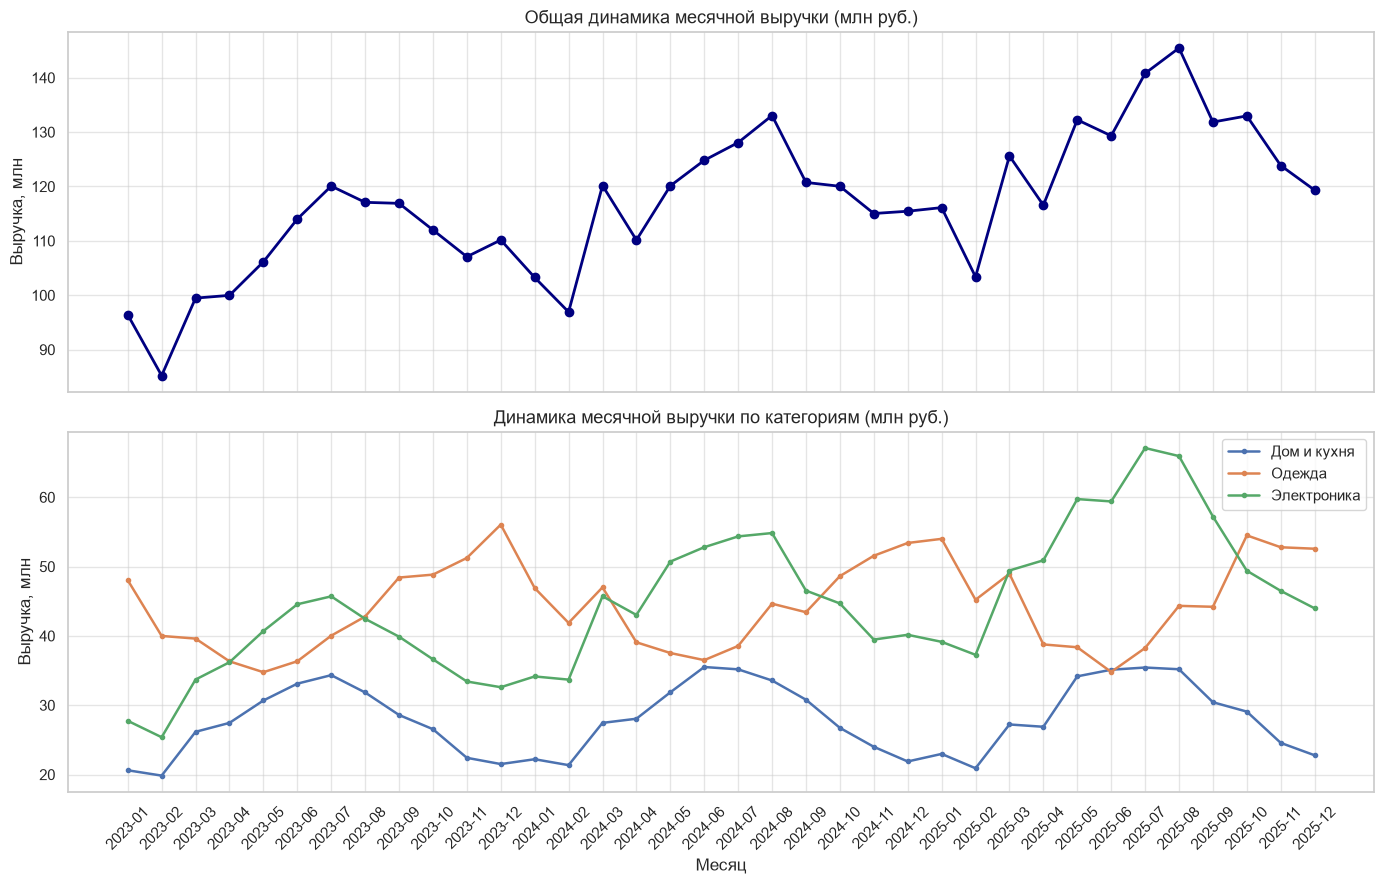

In [16]:
monthly_total = df.groupby("year_month")["revenue"].sum()
monthly_cat = df.pivot_table(index="year_month", columns="category", values="revenue", aggfunc="sum")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

ax1.plot(monthly_total.index, monthly_total.values / 1e6, marker="o", color="navy", linewidth=2)
ax1.set_title("Общая динамика месячной выручки (млн руб.)", fontsize=13)
ax1.set_ylabel("Выручка, млн")

for col in monthly_cat.columns:
    ax2.plot(monthly_cat.index, monthly_cat[col] / 1e6, marker=".", linewidth=1.8, label=col)

ax2.set_title("Динамика месячной выручки по категориям (млн руб.)", fontsize=13)
ax2.set_ylabel("Выручка, млн")
ax2.set_xlabel("Месяц")
ax2.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


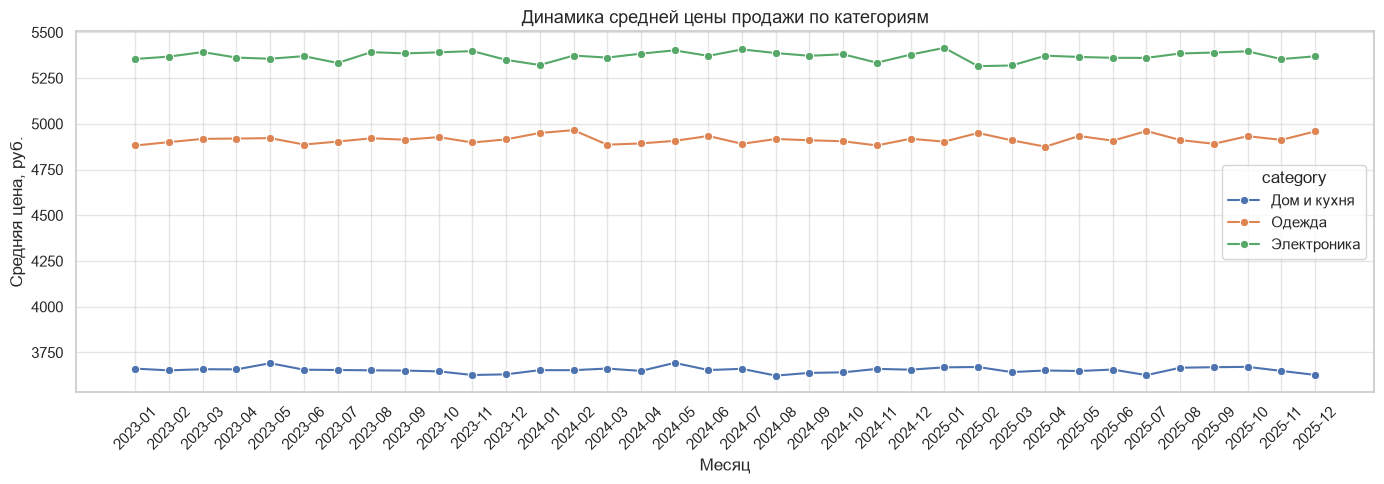

In [17]:
avg_price_cat = df.groupby(["year_month", "category"], as_index=False)["price"].mean()

plt.figure(figsize=(14, 5))
sns.lineplot(data=avg_price_cat, x="year_month", y="price", hue="category", marker="o")
plt.title("Динамика средней цены продажи по категориям", fontsize=13)
plt.xlabel("Месяц")
plt.ylabel("Средняя цена, руб.")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [18]:
store_sales = df.groupby(["city", "store_id"], as_index=False).agg(
    total_qty=("qty", "sum"),
    total_revenue=("revenue", "sum"),
)

fig = px.bar(
    store_sales,
    x="store_id",
    y="total_qty",
    color="city",
    text_auto=".2s",
    title="Объём проданных единиц товара по магазинам и городам",
    labels={"store_id": "Магазин", "total_qty": "Продано, шт.", "city": "Город"},
)
fig.show(renderer="iframe")


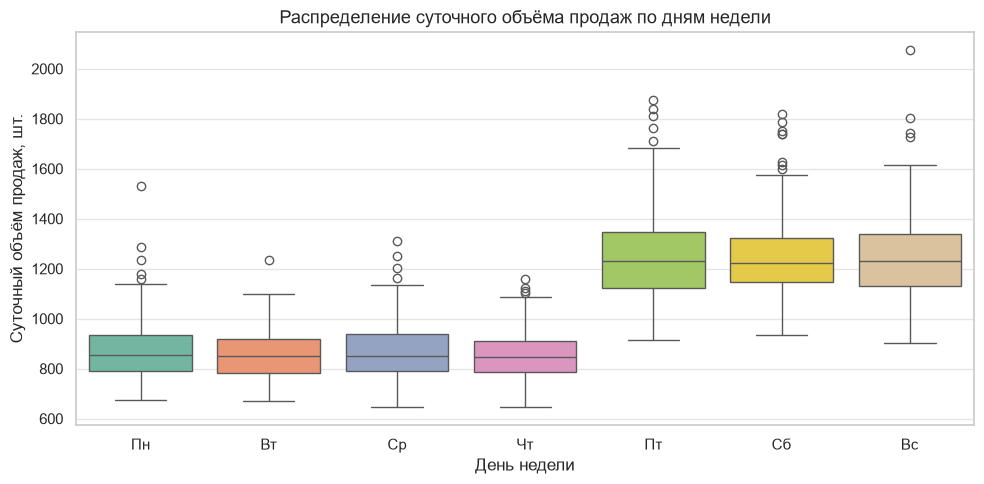

In [19]:
daily_sales = df.groupby(["date", "day_num", "day_of_week"], as_index=False)["qty"].sum().sort_values("day_num")

plt.figure(figsize=(10, 5))
sns.boxplot(data=daily_sales, x="day_of_week", y="qty", palette="Set2", hue="day_of_week", legend=False)
plt.title("Распределение суточного объёма продаж по дням недели", fontsize=13)
plt.xlabel("День недели")
plt.ylabel("Суточный объём продаж, шт.")
plt.tight_layout()
plt.show()


In [20]:
pay_share = df["payment_method"].fillna("Не указано (пропуск)").value_counts().reset_index()
pay_share.columns = ["payment_method", "count"]

fig = px.pie(
    pay_share,
    names="payment_method",
    values="count",
    hole=0.4,
    title="Структура транзакций по способам оплаты",
)
fig.show(renderer="iframe")


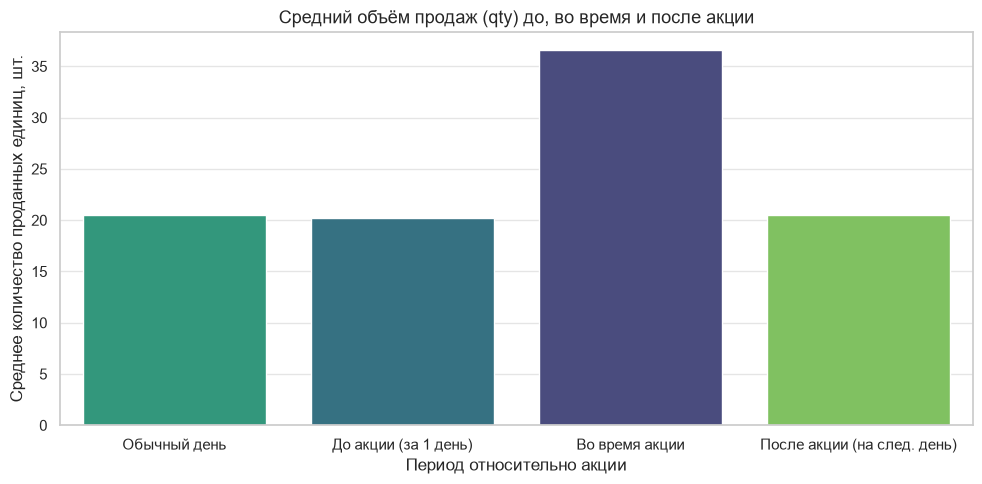

In [21]:
# Определяем статус дня относительно акции по каждому магазину и товару
df_sorted = df.sort_values(["store_id", "product", "date"]).copy()
prev_promo = df_sorted.groupby(["store_id", "product"])["promo"].shift(1).fillna(0)
next_promo = df_sorted.groupby(["store_id", "product"])["promo"].shift(-1).fillna(0)

conditions = [
    df_sorted["promo"] == 1,
    (df_sorted["promo"] == 0) & (next_promo == 1),
    (df_sorted["promo"] == 0) & (prev_promo == 1),
]
choices = ["Во время акции", "До акции (за 1 день)", "После акции (на след. день)"]
df_sorted["promo_stage"] = np.select(conditions, choices, default="Обычный день")

stage_order = ["Обычный день", "До акции (за 1 день)", "Во время акции", "После акции (на след. день)"]
promo_effect = df_sorted.groupby("promo_stage", as_index=False)["qty"].mean()

plt.figure(figsize=(10, 5))
sns.barplot(data=promo_effect, x="promo_stage", y="qty", order=stage_order, palette="viridis", hue="promo_stage", legend=False)
plt.title("Средний объём продаж (qty) до, во время и после акции", fontsize=13)
plt.xlabel("Период относительно акции")
plt.ylabel("Среднее количество проданных единиц, шт.")
plt.tight_layout()
plt.show()
